# 1일차 · 바이어 EDA — 연체 바이어 분포

- 원본: `data/day1/d1_buyers_raw.xlsx`(시트 `buyers`) · 결제조건 코드표: `workbench/day1/outputs/d1_code_table.csv` — **읽기만** 함
- 정리 규칙과 코드: `scripts/d1_eda_prep.py` (R1~R5). 분석 표는 메모리에서만 만들고 파일로 저장하지 않음
- 연체 바이어 = `max_dpd_days > 0`. 연체일을 모르는 행(`-` · `확인중`)은 비율의 분모 · 분자에서 모두 뺌
- 결과: `workbench/day1/outputs/charts/*.png` · `workbench/day1/outputs/d1_eda_notes.md`

In [1]:
# 1) 분석용 표 만들기 — 경로는 저장소 맨 위 폴더 기준
import os, sys
from pathlib import Path

root = Path.cwd()
while not (root / "pyproject.toml").exists():
    root = root.parent
os.chdir(root)
sys.path.insert(0, str(root / "scripts"))

import pandas as pd
from d1_eda_prep import build_analysis_table

raw, df = build_analysis_table()
print(f"원본 {len(raw)}행 → 분석 표 {len(df)}행 (buyer_id 고유 {df['buyer_id'].nunique()})")
print("중복으로 뺀 행(엑셀 행):", sorted(set(raw['excel_row']) - set(df['excel_row'])))
print("연체일 정리:", df['dpd_flag'].replace('', '그대로').value_counts().to_dict())
print(df.loc[df['dpd_flag'] != '', ['buyer_id', 'excel_row', 'dpd_raw', 'max_dpd_days', 'dpd_flag']].to_string(index=False))
print("국가명 미매핑:", int(df['country_std'].isna().sum()), "· 코드표 없음:", int((df['payment_code'] == '코드표 없음').sum()))

known = df[df['max_dpd_days'].notna()]
n_over = int(known['is_overdue'].sum())
print(f"연체일 확인 {len(known)}곳 중 연체 {n_over}곳 = {n_over}/{len(known)} = {n_over/len(known):.1%}")

원본 153행 → 분석 표 150행 (buyer_id 고유 150)
중복으로 뺀 행(엑셀 행): [63, 107, 123]
연체일 정리: {'그대로': 146, '단위 제거': 2, '확인 필요': 2}
buyer_id  excel_row  dpd_raw  max_dpd_days dpd_flag
    B048         49      90일          90.0    단위 제거
    B058         59        -           NaN    확인 필요
    B066         68      확인중           NaN    확인 필요
    B147        151 381 days         381.0    단위 제거
국가명 미매핑: 0 · 코드표 없음: 0
연체일 확인 148곳 중 연체 25곳 = 25/148 = 16.9%


In [2]:
# 2) 차트 공통 설정 — 한글 글꼴 NanumGothic
import matplotlib.pyplot as plt
from matplotlib import font_manager

FONT = root / "tools/fonts/NanumGothic-Regular.ttf"
font_manager.fontManager.addfont(str(FONT))
plt.rcParams.update({
    "font.family": font_manager.FontProperties(fname=str(FONT)).get_name(),
    "axes.unicode_minus": False,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#8A8A8A", "axes.grid": True, "grid.color": "#E3E3E3", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
})
BAR, MUTED, INK = "#3D6FB0", "#A9BEDC", "#333333"
CHARTS = root / "workbench/day1/outputs/charts"
CHARTS.mkdir(parents=True, exist_ok=True)
print("글꼴:", plt.rcParams["font.family"], "· 저장 폴더:", CHARTS.relative_to(root))

글꼴: ['NanumGothic'] · 저장 폴더: workbench\day1\outputs\charts


연체일 확인 148곳 · 0일 123곳 · 0일 초과 25곳
0일 초과 요약: {'count': 25.0, 'mean': 81.0, 'std': 114.0, 'min': 3.0, '25%': 15.0, '50%': 31.0, '75%': 74.0, 'max': 381.0}
구간(코드표 aging_bucket): {'1-30': 12, '31-60': 4, '61-90': 5, '91+': 4}


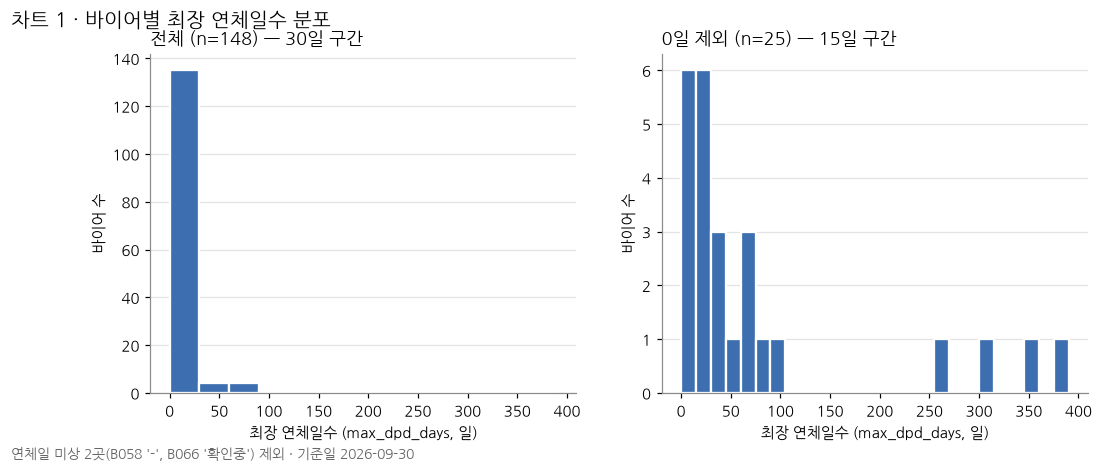

In [3]:
# 3) 차트 1 — max_dpd_days 분포 (전체 / 0일 제외)
dpd = known['max_dpd_days']
pos = dpd[dpd > 0]
print(f"연체일 확인 {len(dpd)}곳 · 0일 {int((dpd == 0).sum())}곳 · 0일 초과 {len(pos)}곳")
print("0일 초과 요약:", pos.describe().round(1).to_dict())
buckets = pd.cut(pos, [0, 30, 60, 90, float('inf')], labels=['1-30', '31-60', '61-90', '91+'])
print("구간(코드표 aging_bucket):", buckets.value_counts().sort_index().to_dict())

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
bins = range(0, int(dpd.max()) + 31, 30)
axes[0].hist(dpd, bins=bins, color=BAR, edgecolor="white", linewidth=1.5)
axes[0].set_title(f"전체 (n={len(dpd)}) — 30일 구간", loc="left")
axes[1].hist(pos, bins=range(0, int(pos.max()) + 16, 15), color=BAR, edgecolor="white", linewidth=1.5)
axes[1].set_title(f"0일 제외 (n={len(pos)}) — 15일 구간", loc="left")
for ax in axes:
    ax.set_xlabel("최장 연체일수 (max_dpd_days, 일)")
    ax.set_ylabel("바이어 수")
    ax.grid(axis="x", visible=False)
fig.suptitle("차트 1 · 바이어별 최장 연체일수 분포", x=0.01, ha="left", fontsize=13)
fig.text(0.01, -0.04, f"연체일 미상 {len(df) - len(dpd)}곳(B058 '-', B066 '확인중') 제외 · 기준일 2026-09-30",
         fontsize=9, color="#666666")
fig.savefig(CHARTS / "d1_chart1_dpd_hist.png")
plt.show()

### 차트 1 해석

1. 연체일을 아는 148곳 중 123곳(83.1%)은 0일이고, 연체 바이어는 25곳(16.9% = 25/148)입니다. 전체 그림은 0일 막대에 묻혀 꼬리가 거의 보이지 않아 0일을 뺀 그림을 함께 봐야 합니다.
2. 연체 25곳의 중앙값은 31일이지만 평균은 81일입니다. 코드표 aging 구간으로 1-30일 12곳 · 31-60일 4곳 · 61-90일 5곳 · 91일 이상 4곳이라, 대부분은 짧은 지연이고 소수의 장기 연체가 평균을 끌어올립니다.
3. 91일 이상 4곳(B071 269일 · B083 305일 · B044 355일 · B147 381일)은 따로 떨어져 있습니다. 이 중 B044 · B147은 K-SURE 미부보(N)입니다. 원본 연체일만 본 값이라, 인보이스 원장으로 재계산해 대조하는 것은 `확인 필요`입니다.

country_code country_std  바이어수  연체수  연체비율
         MEX         멕시코     6    4 66.7%
         THA          태국     5    2 40.0%
         TWN          대만     5    2 40.0%
         ARE      아랍에미리트     6    2 33.3%
         IDN       인도네시아     7    2 28.6%
         TUR        튀르키예     7    2 28.6%
         BRA         브라질     4    1 25.0%
         USA          미국    18    4 22.2%
         DEU          독일    12    2 16.7%
         POL         폴란드     6    1 16.7%
11위 이하 중 상위 10위와 비율이 같은 국가: []


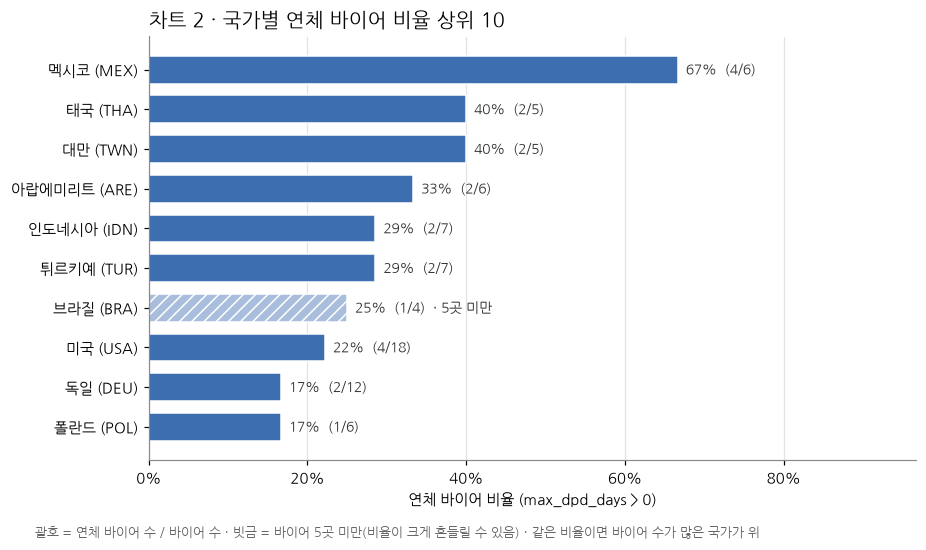

In [4]:
# 4) 차트 2 — 국가별 연체 바이어 비율 상위 10
by_c = (known.groupby(['country_code', 'country_std'])
        .agg(바이어수=('buyer_id', 'size'), 연체수=('is_overdue', 'sum')).reset_index())
by_c['연체수'] = by_c['연체수'].astype(int)
by_c['연체비율'] = by_c['연체수'] / by_c['바이어수']
by_c = by_c.sort_values(['연체비율', '바이어수'], ascending=[False, False]).reset_index(drop=True)
top = by_c.head(10)
print(top.assign(연체비율=top['연체비율'].map('{:.1%}'.format)).to_string(index=False))
print("11위 이하 중 상위 10위와 비율이 같은 국가:",
      by_c.iloc[10:][by_c.iloc[10:]['연체비율'] == top['연체비율'].iloc[-1]]['country_code'].tolist())

small = top['바이어수'] < 5
fig, ax = plt.subplots(figsize=(9, 5))
y = range(len(top))[::-1]
bars = ax.barh(list(y), top['연체비율'], color=[MUTED if s else BAR for s in small],
               hatch=['///' if s else '' for s in small], edgecolor="white", height=0.7)
ax.set_yticks(list(y), [f"{n} ({c})" for n, c in zip(top['country_std'], top['country_code'])])
for yi, (r, k, n, s) in zip(y, top[['연체비율', '연체수', '바이어수']].assign(s=small).values):
    ax.text(r + 0.01, yi, f"{r:.0%}  ({int(k)}/{int(n)}){'  · 5곳 미만' if s else ''}",
            va="center", fontsize=9, color=INK)
ax.set_xlim(0, max(top['연체비율']) * 1.45)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlabel("연체 바이어 비율 (max_dpd_days > 0)")
ax.grid(axis="y", visible=False)
ax.set_title("차트 2 · 국가별 연체 바이어 비율 상위 10", loc="left", fontsize=13)
fig.text(0.01, -0.03, "괄호 = 연체 바이어 수 / 바이어 수 · 빗금 = 바이어 5곳 미만(비율이 크게 흔들릴 수 있음) · "
         "같은 비율이면 바이어 수가 많은 국가가 위", fontsize=8.5, color="#666666")
fig.savefig(CHARTS / "d1_chart2_country_overdue_top10.png")
plt.show()

### 차트 2 해석

1. 멕시코가 67%(4/6)로 가장 높고, 태국 · 대만 40%(2/5), 아랍에미리트 33%(2/6)가 뒤를 잇습니다. 다만 상위 10개국 중 8곳이 바이어 7곳 이하라 1곳만 달라져도 비율이 14~25%p 움직입니다.
2. 바이어가 가장 많은 미국(4/18, 22%)과 독일(2/12, 17%)은 수가 많아 비율이 상대적으로 안정적입니다. 태국 2곳(B044 355일 · B147 381일)은 연체 바이어 수는 적어도 연체 기간이 가장 깁니다.
3. 바이어 5곳 미만 국가는 4곳(브라질 4 · 이집트 4 · 말레이시아 3 · 나이지리아 3)이고, 상위 10에는 브라질(1/4)만 들어 빗금으로 표시했습니다. 분모는 연체일을 아는 바이어 기준이라 아랍에미리트는 B066을 뺀 6곳입니다. 연체 0곳인 7개국은 상위 10에 들지 않았습니다.

   결제방식(표준 코드)  바이어수  연체일_미상  연체_바이어수 연체_바이어_비율
        TT_ADV    10       0        0      0.0%
TT_SPLIT_30_70     8       0        1     12.5%
            OA    87       1       18     20.9%
            DA    24       1        5     21.7%
            DP     4       0        0      0.0%
      LC_SIGHT    10       0        0      0.0%
     LC_USANCE     4       0        0      0.0%
         검토 필요     3       0        1     33.3%
            합계   150       2       25     16.9%


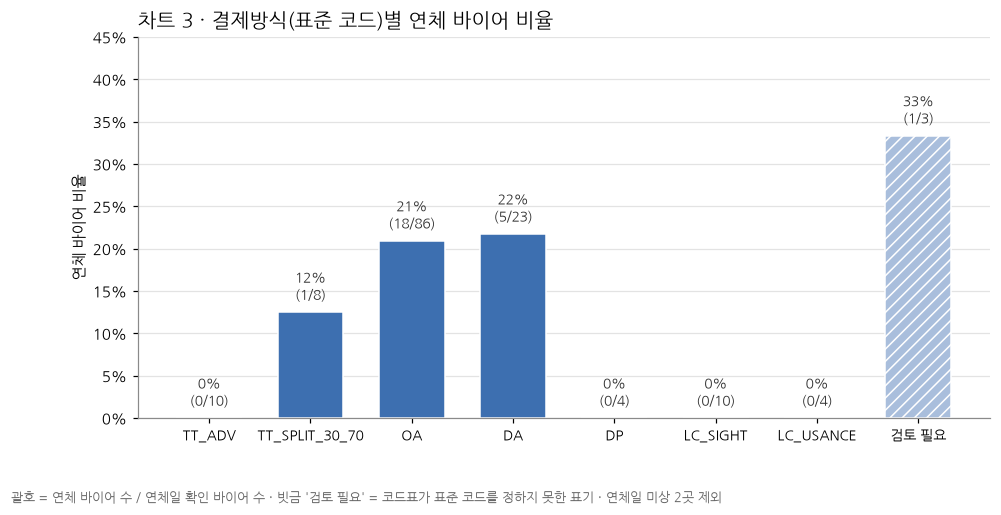

In [5]:
# 5) 차트 3 — 결제방식(표준 코드)별 연체 바이어 비율 + 표
ORDER = ['TT_ADV', 'TT_SPLIT_30_70', 'OA', 'DA', 'DP', 'LC_SIGHT', 'LC_USANCE', '검토 필요', '코드표 없음']
by_p = (df.groupby('payment_code')
        .agg(바이어수=('buyer_id', 'size'),
             연체일_미상=('max_dpd_days', lambda s: int(s.isna().sum())),
             연체_바이어수=('is_overdue', lambda s: int(s.sum()))))
by_p = by_p.reindex([o for o in ORDER if o in by_p.index])
by_p['연체_바이어_비율'] = by_p['연체_바이어수'] / (by_p['바이어수'] - by_p['연체일_미상'])
pay_table = by_p.reset_index().rename(columns={'payment_code': '결제방식(표준 코드)'})
total = pd.DataFrame([{'결제방식(표준 코드)': '합계', '바이어수': int(by_p['바이어수'].sum()),
                       '연체일_미상': int(by_p['연체일_미상'].sum()), '연체_바이어수': int(by_p['연체_바이어수'].sum())}])
total['연체_바이어_비율'] = total['연체_바이어수'] / (total['바이어수'] - total['연체일_미상'])
pay_table = pd.concat([pay_table, total], ignore_index=True)
print(pay_table.assign(연체_바이어_비율=pay_table['연체_바이어_비율'].map('{:.1%}'.format)).to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 4.5))
x = range(len(by_p))
review = [i == '검토 필요' for i in by_p.index]
ax.bar(list(x), by_p['연체_바이어_비율'], color=[MUTED if r else BAR for r in review],
       hatch=['///' if r else '' for r in review], edgecolor="white", width=0.65)
for xi, (r, k, n, u) in zip(x, by_p[['연체_바이어_비율', '연체_바이어수', '바이어수', '연체일_미상']].values):
    ax.text(xi, r + 0.01, f"{r:.0%}\n({int(k)}/{int(n - u)})", ha="center", va="bottom", fontsize=9, color=INK)
ax.set_xticks(list(x), by_p.index, rotation=0, fontsize=9)
ax.set_ylim(0, by_p['연체_바이어_비율'].max() * 1.35)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_ylabel("연체 바이어 비율")
ax.grid(axis="x", visible=False)
ax.set_title("차트 3 · 결제방식(표준 코드)별 연체 바이어 비율", loc="left", fontsize=13)
fig.text(0.01, -0.06, "괄호 = 연체 바이어 수 / 연체일 확인 바이어 수 · 빗금 '검토 필요' = 코드표가 표준 코드를 정하지 못한 표기 · "
         "연체일 미상 2곳 제외", fontsize=8.5, color="#666666")
fig.savefig(CHARTS / "d1_chart3_payment_overdue.png")
plt.show()

### 차트 3 해석

1. 연체 바이어는 OA(18/86, 20.9%)와 DA(5/23, 21.7%)에 모여 있습니다. 연체 25곳 중 23곳이 이 두 방식이고, 선적 후 대금을 받는(수출자가 위험을 지는) 조건입니다.
2. TT_ADV · DP · LC_SIGHT · LC_USANCE는 모두 0%이고, TT_SPLIT_30_70은 12.5%(1/8, B087)입니다. 이 다섯 방식을 합쳐도 36곳이라 '0%'를 '위험이 없다'로 일반화하기에는 표본이 작습니다.
3. '검토 필요' 3곳 중 연체 1곳은 B085(`10% T/T advance + 90% O/A 90 days`, 22일)입니다. 대부분이 사후송금 조건이라 OA와 비슷하게 볼 수도 있지만, 표준 코드는 사람이 정해야 합니다. 이 차트는 결제방식과 연체가 함께 나타난다는 것만 보여 주며, 결제방식이 연체의 원인이라는 근거는 아닙니다.

In [6]:
# 6) d1_eda_notes.md 저장 — 해석 3줄은 위 마크다운 셀과 같은 문장
NOTES = {
    1: """1. 연체일을 아는 148곳 중 123곳(83.1%)은 0일이고, 연체 바이어는 25곳(16.9% = 25/148)입니다. 전체 그림은 0일 막대에 묻혀 꼬리가 거의 보이지 않아 0일을 뺀 그림을 함께 봐야 합니다.
2. 연체 25곳의 중앙값은 31일이지만 평균은 81일입니다. 코드표 aging 구간으로 1-30일 12곳 · 31-60일 4곳 · 61-90일 5곳 · 91일 이상 4곳이라, 대부분은 짧은 지연이고 소수의 장기 연체가 평균을 끌어올립니다.
3. 91일 이상 4곳(B071 269일 · B083 305일 · B044 355일 · B147 381일)은 따로 떨어져 있습니다. 이 중 B044 · B147은 K-SURE 미부보(N)입니다. 원본 연체일만 본 값이라, 인보이스 원장으로 재계산해 대조하는 것은 `확인 필요`입니다.""",
    2: """1. 멕시코가 67%(4/6)로 가장 높고, 태국 · 대만 40%(2/5), 아랍에미리트 33%(2/6)가 뒤를 잇습니다. 다만 상위 10개국 중 8곳이 바이어 7곳 이하라 1곳만 달라져도 비율이 14~25%p 움직입니다.
2. 바이어가 가장 많은 미국(4/18, 22%)과 독일(2/12, 17%)은 수가 많아 비율이 상대적으로 안정적입니다. 태국 2곳(B044 355일 · B147 381일)은 연체 바이어 수는 적어도 연체 기간이 가장 깁니다.
3. 바이어 5곳 미만 국가는 4곳(브라질 4 · 이집트 4 · 말레이시아 3 · 나이지리아 3)이고, 상위 10에는 브라질(1/4)만 들어 빗금으로 표시했습니다. 분모는 연체일을 아는 바이어 기준이라 아랍에미리트는 B066을 뺀 6곳입니다. 연체 0곳인 7개국은 상위 10에 들지 않았습니다.""",
    3: """1. 연체 바이어는 OA(18/86, 20.9%)와 DA(5/23, 21.7%)에 모여 있습니다. 연체 25곳 중 23곳이 이 두 방식이고, 선적 후 대금을 받는(수출자가 위험을 지는) 조건입니다.
2. TT_ADV · DP · LC_SIGHT · LC_USANCE는 모두 0%이고, TT_SPLIT_30_70은 12.5%(1/8, B087)입니다. 이 다섯 방식을 합쳐도 36곳이라 '0%'를 '위험이 없다'로 일반화하기에는 표본이 작습니다.
3. '검토 필요' 3곳 중 연체 1곳은 B085(`10% T/T advance + 90% O/A 90 days`, 22일)입니다. 대부분이 사후송금 조건이라 OA와 비슷하게 볼 수도 있지만, 표준 코드는 사람이 정해야 합니다. 이 차트는 결제방식과 연체가 함께 나타난다는 것만 보여 주며, 결제방식이 연체의 원인이라는 근거는 아닙니다.""",
}

def md_table(t):
    t = t.copy()
    t['연체_바이어_비율'] = t['연체_바이어_비율'].map('{:.1%}'.format)
    t = t.rename(columns={'바이어수': '바이어 수', '연체일_미상': '연체일 미상', '연체_바이어수': '연체 바이어 수',
                          '연체_바이어_비율': '연체 바이어 비율'})
    lines = ['| ' + ' | '.join(t.columns) + ' |', '|' + '---|' * len(t.columns)]
    lines += ['| ' + ' | '.join(str(v) for v in row) + ' |' for row in t.itertuples(index=False)]
    return '\n'.join(lines)

text = f"""# 1일차 · 바이어 EDA 노트

- 노트북: `workbench/day1/notebooks/d1_eda.ipynb` · 정리 규칙과 코드: `scripts/d1_eda_prep.py`
- 원본 `data/day1/d1_buyers_raw.xlsx`(153행) → buyer_id 중복 3행 제거 → **150곳**. 결제조건은 `d1_code_table.csv`로 표준 코드 변환
- 연체 바이어 = `max_dpd_days > 0`. 연체일 미상 2곳(B058 `-` · B066 `확인중`)은 비율의 분모 · 분자에서 뺌
- 비율 = 연체 바이어 수 ÷ (바이어 수 − 연체일 미상)

## 차트 1 · 최장 연체일수 분포

![차트 1](charts/d1_chart1_dpd_hist.png)

{NOTES[1]}

## 차트 2 · 국가별 연체 바이어 비율 상위 10

![차트 2](charts/d1_chart2_country_overdue_top10.png)

{NOTES[2]}

## 차트 3 · 결제방식(표준 코드)별 연체 바이어 비율

![차트 3](charts/d1_chart3_payment_overdue.png)

{NOTES[3]}

### 결제방식별 바이어 수 · 연체 바이어 수 · 연체 바이어 비율

{md_table(pay_table)}
"""
out = root / "workbench/day1/outputs/d1_eda_notes.md"
out.write_text(text, encoding="utf-8")
print("저장:", out.relative_to(root))

저장: workbench\day1\outputs\d1_eda_notes.md
